# Gaze-Object Scale-Aware Gaussian Video Demonstration

Render the scale-aware Gaussian gaze-object result back onto a world-camera video. The default recording is selected because it has many scored frames in the Gaussian output.


## Setup

In [2]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DATASET_ROOT = Path("/home/julius/datasets/seminar_object_detection")
VIDEO_ROOT = DATASET_ROOT / "iAssistADL_dataset_export_2026-05-18" / "world_camera_videos"
LOWER_ROOT = DATASET_ROOT / "lower_feature_outcome"
UPPER_ROOT = DATASET_ROOT / "upper_feature_outcome"
OUTPUT_ROOT = DATASET_ROOT / "video_demostration"

GAZE_ROOT = LOWER_ROOT / "gaze_xy_filled_sensor_csv"
YOLO_ROOT = LOWER_ROOT / "yolo_object_outcome_csv"
GAUSSIAN_ROOT = UPPER_ROOT / "gaze_object_features" / "scale_aware_gaussian_frame_aggregation"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SELECTED_PARTICIPANT = "IA_4_H_14"
SELECTED_FULL_ID = "IA_4_H_14_Chaos_several_Tasks_combine1"

WINDOW_SECONDS = 30
MAX_GAZE_POINTS_PER_FRAME = 10
MAX_BOXES_TO_DRAW = 8
SCORE_DISPLAY_THRESHOLD = 0.01

video_path = VIDEO_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_world_camera.mp4"
gaze_path = GAZE_ROOT / SELECTED_PARTICIPANT / SELECTED_FULL_ID / "eye_tracker__gaze.csv"
yolo_path = YOLO_ROOT / f"{SELECTED_FULL_ID}_world_camera.csv"
gaussian_frame_path = GAUSSIAN_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_gaze_yolo_scale_aware_gaussian_frame.csv"
gaussian_box_path = GAUSSIAN_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_gaze_yolo_scale_aware_gaussian_frame_boxes.csv"
output_video_path = OUTPUT_ROOT / f"{SELECTED_FULL_ID}_gaze_object_scale_aware_gaussian_demo.mp4"

for path in [video_path, gaze_path, yolo_path, gaussian_frame_path, gaussian_box_path]:
    assert path.exists(), f"Missing file: {path}"

video_path, gaussian_frame_path, gaussian_box_path, output_video_path


(PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_world_camera.mp4'),
 PosixPath('/home/julius/datasets/seminar_object_detection/upper_feature_outcome/gaze_object_features/scale_aware_gaussian_frame_aggregation/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_yolo_scale_aware_gaussian_frame.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/upper_feature_outcome/gaze_object_features/scale_aware_gaussian_frame_aggregation/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_yolo_scale_aware_gaussian_frame_boxes.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_scale_aware_gaussian_demo.mp4'))

## Pick A High-Score Window

The full recording can be long, so this chooses the 30-second window with the most frames whose Gaussian `best_score` is above the score threshold.


In [3]:
gaussian_frame_df = pd.read_csv(gaussian_frame_path)
gaussian_frame_df["best_score"] = pd.to_numeric(gaussian_frame_df["best_score"], errors="coerce")
gaussian_frame_df["score_threshold"] = pd.to_numeric(gaussian_frame_df["score_threshold"], errors="coerce")

cap = cv2.VideoCapture(str(video_path))
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

if not fps or np.isnan(fps):
    fps = 30

window_frames = int(round(WINDOW_SECONDS * fps))
gaussian_frame_df = gaussian_frame_df.sort_values("video_frame_idx").copy()
gaussian_frame_df["is_scored"] = gaussian_frame_df["best_score"] >= gaussian_frame_df["score_threshold"].fillna(SCORE_DISPLAY_THRESHOLD)

rolling_scores = (
    gaussian_frame_df.set_index("video_frame_idx")["is_scored"]
    .reindex(range(frame_count), fill_value=False)
    .astype(int)
    .rolling(window_frames, min_periods=1)
    .sum()
)

best_end_frame = int(rolling_scores.idxmax())
START_FRAME = max(0, best_end_frame - window_frames + 1)
END_FRAME = min(frame_count - 1, START_FRAME + window_frames - 1)

video_info = {
    "fps": fps,
    "frame_count": frame_count,
    "width": width,
    "height": height,
    "start_frame": START_FRAME,
    "end_frame": END_FRAME,
    "window_seconds": (END_FRAME - START_FRAME + 1) / fps,
    "scored_frames_in_window": int(rolling_scores.max()),
}
video_info


{'fps': 30.0,
 'frame_count': 3882,
 'width': 1600,
 'height': 1200,
 'start_frame': 556,
 'end_frame': 1455,
 'window_seconds': 30.0,
 'scored_frames_in_window': 900}

## Load Gaze, YOLO, And Gaussian Scores

In [4]:
gaze_df = pd.read_csv(gaze_path)
yolo_df = pd.read_csv(yolo_path)
gaussian_box_df = pd.read_csv(gaussian_box_path)

for col in ["video_frame_idx", "x", "y"]:
    gaze_df[col] = pd.to_numeric(gaze_df[col], errors="coerce")

for col in ["frame_id", "class_id", "confidence", "x1", "y1", "x2", "y2"]:
    yolo_df[col] = pd.to_numeric(yolo_df[col], errors="coerce")

for col in ["video_frame_idx", "detection_idx_in_frame", "class_id", "confidence", "x1", "y1", "x2", "y2", "mean_score", "max_score"]:
    gaussian_box_df[col] = pd.to_numeric(gaussian_box_df[col], errors="coerce")

gaze_df = gaze_df[np.isfinite(gaze_df["video_frame_idx"])].copy()
gaze_df["video_frame_idx"] = gaze_df["video_frame_idx"].astype(int)
yolo_df = yolo_df[np.isfinite(yolo_df["frame_id"])].copy()
yolo_df["frame_id"] = yolo_df["frame_id"].astype(int)
gaussian_box_df = gaussian_box_df[np.isfinite(gaussian_box_df["video_frame_idx"])].copy()
gaussian_box_df["video_frame_idx"] = gaussian_box_df["video_frame_idx"].astype(int)

gaze_by_frame = {frame: df for frame, df in gaze_df.groupby("video_frame_idx")}
yolo_by_frame = {frame: df for frame, df in yolo_df.groupby("frame_id")}
score_by_frame = {frame: df for frame, df in gaussian_box_df.groupby("video_frame_idx")}
frame_summary_by_frame = gaussian_frame_df.set_index("video_frame_idx").to_dict("index")

print("gaze rows:", len(gaze_df))
print("yolo rows:", len(yolo_df))
print("gaussian box-score rows:", len(gaussian_box_df))


gaze rows: 19565
yolo rows: 31786
gaussian box-score rows: 31786


## Rendering Helpers

In [5]:
def score_to_color(score):
    score = 0.0 if pd.isna(score) else float(score)
    score = max(0.0, min(1.0, score))
    red = int(255 * score)
    green = int(255 * (1.0 - abs(score - 0.5) * 2.0))
    blue = int(255 * (1.0 - score))
    return (blue, green, red)


def draw_label(frame, text, xy, color, font_scale=0.55, thickness=1):
    x, y = int(xy[0]), int(xy[1])
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    cv2.rectangle(frame, (x, y - th - baseline - 4), (x + tw + 6, y), color, -1)
    cv2.putText(frame, text, (x + 3, y - baseline - 2), font, font_scale, (255, 255, 255), thickness, cv2.LINE_AA)


def draw_overlay(frame, frame_idx, frame_gaze, frame_yolo, frame_scores, frame_summary):
    if frame_yolo is not None and not frame_yolo.empty:
        for detection_idx, (_, box) in enumerate(frame_yolo.iterrows()):
            x1, y1, x2, y2 = [int(round(box[c])) for c in ["x1", "y1", "x2", "y2"]]
            cv2.rectangle(frame, (x1, y1), (x2, y2), (55, 55, 55), 1)

    if frame_scores is not None and not frame_scores.empty:
        top_scores = frame_scores.sort_values("mean_score", ascending=False).head(MAX_BOXES_TO_DRAW)
        for rank, (_, box) in enumerate(top_scores.iterrows()):
            score = float(box["mean_score"])
            x1, y1, x2, y2 = [int(round(box[c])) for c in ["x1", "y1", "x2", "y2"]]
            color = score_to_color(score)
            thickness = 4 if rank == 0 and score >= SCORE_DISPLAY_THRESHOLD else 2
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, thickness)
            label = f"class {int(box['class_id'])} score {score:.3f}"
            draw_label(frame, label, (x1, max(18, y1 - 4)), color)

    if frame_gaze is not None and not frame_gaze.empty:
        valid_gaze = frame_gaze[np.isfinite(frame_gaze["x"]) & np.isfinite(frame_gaze["y"])]
        for _, gaze in valid_gaze.tail(MAX_GAZE_POINTS_PER_FRAME).iterrows():
            gx, gy = int(round(gaze["x"])), int(round(gaze["y"]))
            cv2.circle(frame, (gx, gy), 8, (0, 255, 255), -1)
            cv2.circle(frame, (gx, gy), 12, (0, 0, 0), 2)

    best_class = frame_summary.get("best_class", "NA") if frame_summary else "NA"
    best_score = frame_summary.get("best_score", 0.0) if frame_summary else 0.0
    status = f"{SELECTED_FULL_ID} | frame {frame_idx} | Gaussian best {best_class} score {float(best_score):.3f}"
    draw_label(frame, status, (12, 30), (30, 30, 30), font_scale=0.6, thickness=1)
    return frame


## Preview One Frame

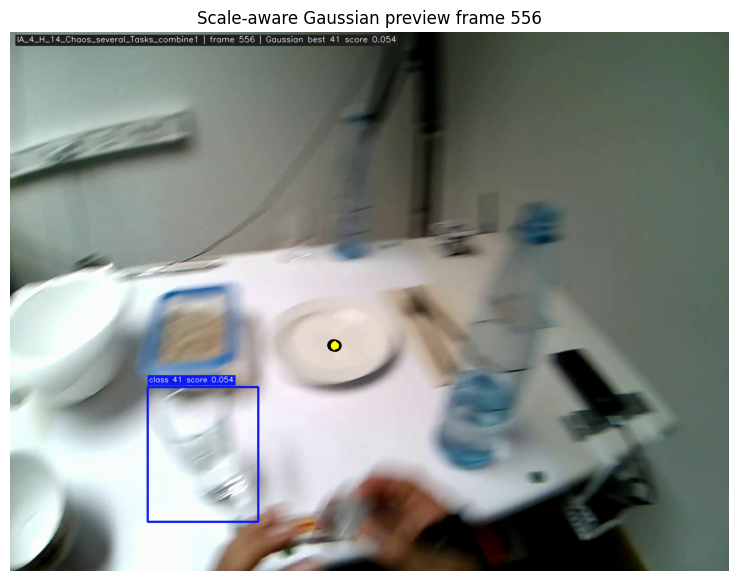

In [6]:
preview_frame_idx = START_FRAME
cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, preview_frame_idx)
ok, preview = cap.read()
cap.release()
assert ok, f"Could not read frame {preview_frame_idx}"

preview = draw_overlay(
    preview,
    preview_frame_idx,
    gaze_by_frame.get(preview_frame_idx),
    yolo_by_frame.get(preview_frame_idx),
    score_by_frame.get(preview_frame_idx),
    frame_summary_by_frame.get(preview_frame_idx, {}),
)

preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 7))
plt.imshow(preview_rgb)
plt.axis("off")
plt.title(f"Scale-aware Gaussian preview frame {preview_frame_idx}")
plt.show()


## Render Demo Video

In [7]:
cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(str(output_video_path), fourcc, fps, (width, height))
assert writer.isOpened(), f"Could not open writer: {output_video_path}"

for frame_idx in tqdm(range(START_FRAME, END_FRAME + 1), desc="Rendering Gaussian gaze-object demo", unit="frame"):
    ok, frame = cap.read()
    if not ok:
        print(f"Stopped early at frame {frame_idx}")
        break

    frame = draw_overlay(
        frame,
        frame_idx,
        gaze_by_frame.get(frame_idx),
        yolo_by_frame.get(frame_idx),
        score_by_frame.get(frame_idx),
        frame_summary_by_frame.get(frame_idx, {}),
    )
    writer.write(frame)

writer.release()
cap.release()

print(f"Saved: {output_video_path}")


Rendering Gaussian gaze-object demo:   0%|          | 0/900 [00:00<?, ?frame/s]

Saved: /home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_scale_aware_gaussian_demo.mp4


## Optional: Inspect Box Scores For The Selected Window

In [8]:
box_scores_in_window_df = gaussian_box_df[
    (gaussian_box_df["video_frame_idx"] >= START_FRAME)
    & (gaussian_box_df["video_frame_idx"] <= END_FRAME)
].sort_values(["video_frame_idx", "mean_score"], ascending=[True, False])

box_scores_in_window_df.head(20)


,video_frame_idx,detection_idx_in_frame,class_id,confidence,x1,y1,x2,y2,sigma,valid_gaze_sample_count,mean_score,max_score
4121,556,0,41,0.365112,306.228210,789.630615,552.098206,1089.969971,194.072012,4,0.053826,0.054417
4124,557,2,60,0.474689,8.053589,411.597595,1481.436157,1200.000000,835.528956,4,0.470417,0.470679
4126,557,4,39,0.415461,918.568848,392.699280,1133.058960,885.218201,268.598630,4,0.222137,0.225729
4125,557,3,41,0.471493,256.163116,819.773071,492.524048,1089.460571,179.302703,4,0.022932,0.024867
4123,557,1,45,0.581113,0.401497,565.804565,198.020508,879.862976,185.530293,4,0.001763,0.001916
4122,557,0,67,0.587406,1128.207764,704.548889,1312.262451,861.125549,120.822575,4,0.000122,0.000132
4133,558,6,60,0.311402,7.848358,411.558777,1444.334839,1199.194214,819.124989,4,0.308173,0.308375
4132,558,5,71,0.319916,482.168732,623.636292,768.112671,820.749634,173.650228,4,0.252449,0.256564
4129,558,2,39,0.449677,914.287842,395.591125,1102.389404,701.526978,179.568193,4,0.108539,0.109939
4131,558,4,39,0.357374,604.582031,191.145950,694.723999,511.720886,166.503652,4,0.040090,0.042480
